In [1]:
from pathlib import Path
import json, torch, pandas as pd
import os

os.chdir('..')

# point to one run  ────────────────────────────────────────────────
RUN_DIR = Path("eval_results/Qwen__Qwen2.5-14B_2025-05-20_18-25-42")

# load the JSON index  ────────────────────────────────────────────
with open(RUN_DIR / "index.json", encoding="utf-8") as fp:
    rows = json.load(fp)

df = pd.DataFrame(rows)
print("Rows:", len(df))
df.head()          # interactive preview in Jupyter


Rows: 402


,id,question,ground_answer_text,model_answers_text,extracted_model_answers,extracted_ground_answer,majority_answer,correct,output_tokens,entropy_file,forward_kl_file,layer_avg_logp_file,topk_final_log_probs_file,topk_final_ids_file,topk_final_tokens_file,topk_layer_log_probs_file,topk_layer_ids_file,topk_layer_tokens_file
0,216,\nQUESTION:\nCompute\n\[\cos^3 \frac{2 \pi}{7}...,\boxed{-\frac{1}{2}},[Let $\alpha = e^{2 \pi i / 7}.$ Then $\alpha...,[\frac{1}{2}],-\frac{1}{2},\frac{1}{2},False,"[10061, 57960, 7141, 284, 384, 47822, 17, 1124...",216_entropy.pt,216_forward_kl.pt,216_layer_avg_logp.pt,216_topk_final_log_probs.pt,216_topk_final_ids.pt,216_topk_final_tokens.pt,216_topk_layer_log_probs.pt,216_topk_layer_ids.pt,216_topk_layer_tokens.pt
1,553,\nQUESTION:\nThe matrices\n\[\mathbf{A} = \ren...,\boxed{\frac{56}{5}},"[To solve for \(x\), \(y\), and \(z\) in the g...",[\frac{56}{5}],\frac{56}{5},\frac{56}{5},True,"[1249, 11625, 369, 17767, 87, 59, 701, 17767, ...",553_entropy.pt,553_forward_kl.pt,553_layer_avg_logp.pt,553_topk_final_log_probs.pt,553_topk_final_ids.pt,553_topk_final_tokens.pt,553_topk_layer_log_probs.pt,553_topk_layer_ids.pt,553_topk_layer_tokens.pt
2,98,\nQUESTION:\nGiven $\|\mathbf{v}\| = 5$ and $\...,\boxed{5},[The projection of $\mathbf{v}$ onto $\mathbf{...,[5],5,5,True,"[785, 21615, 315, 57960, 10374, 13233, 90, 85,...",98_entropy.pt,98_forward_kl.pt,98_layer_avg_logp.pt,98_topk_final_log_probs.pt,98_topk_final_ids.pt,98_topk_final_tokens.pt,98_topk_layer_log_probs.pt,98_topk_layer_ids.pt,98_topk_layer_tokens.pt
3,287,"\nQUESTION:\nIn triangle $ABC,$ $\angle C = 90...",\boxed{\frac{\sqrt{6}}{3}},[Let $D$ be the foot of the altitude from $C$ ...,[0],\frac{\sqrt{6}}{3},0,False,"[10061, 400, 35, 3, 387, 279, 4478, 315, 279, ...",287_entropy.pt,287_forward_kl.pt,287_layer_avg_logp.pt,287_topk_final_log_probs.pt,287_topk_final_ids.pt,287_topk_final_tokens.pt,287_topk_layer_log_probs.pt,287_topk_layer_ids.pt,287_topk_layer_tokens.pt
4,356,\nQUESTION:\nThe set of vectors $\mathbf{v}$ s...,\boxed{y = -2x},[The projection of $\mathbf{v}$ onto $\begin{p...,[-2x],y = -2x,-2x,True,"[785, 21615, 315, 57960, 10374, 13233, 90, 85,...",356_entropy.pt,356_forward_kl.pt,356_layer_avg_logp.pt,356_topk_final_log_probs.pt,356_topk_final_ids.pt,356_topk_final_tokens.pt,356_topk_layer_log_probs.pt,356_topk_layer_ids.pt,356_topk_layer_tokens.pt


In [3]:
# all wrong answers
wrong = df[~df.correct]
wrong[["id", "question", "model_answers_text"]].head()


,id,question,model_answers_text
0,216,\nQUESTION:\nCompute\n\[\cos^3 \frac{2 \pi}{7}...,[Let $\alpha = e^{2 \pi i / 7}.$ Then $\alpha...
2,287,"\nQUESTION:\nIn triangle $ABC,$ $\angle C = 90...",[Let $D$ be the foot of the altitude from $C$ ...
4,1119,\nQUESTION:\nThere exist two complex numbers $...,[Let $c_1 = -5 + 3i + (8 - i - (-5 + 3i)) \ope...
5,1229,\nQUESTION:\nFind $\csc (-120^\circ).$\FULL SO...,[We know that $\csc \theta = \frac{1}{\sin \th...
7,516,\nQUESTION:\nOne line is parameterized by\n\[\...,[To find the cosine of the acute angle $\theta...


In [5]:
row = wrong.iloc[0]          # pick first mistake

# helper for shorter syntax
load = lambda key: torch.load(RUN_DIR / row[f"{key}_file"], weights_only=False)

topk_lp    = load("topk_final_log_probs")   # (seq_len , K)
topk_ids   = load("topk_final_ids")         # (seq_len , K)
topk_toks  = load("topk_final_tokens")      # list[list[str]]
entropy    = load("entropy")                # (n_layers , seq_len)

print("Question:", row.question[:120], "…")
print("Model answer:", row.model_answers_text[0])
print("Log-probs shape :", topk_lp.shape)
print("Top-5 tokens @ first position:", topk_toks[0])


Question: 
QUESTION:
Compute
\[\cos^3 \frac{2 \pi}{7} + \cos^3 \frac{4 \pi}{7} + \cos^3 \frac{8 \pi}{7}.\]\FULL SOLUTION:
 …
Model answer: Let $\alpha = e^{2 \pi i / 7}.$  Then $\alpha^7 = 1,$ so
\begin{align*}
\cos^3 \frac{2 \pi}{7} + \cos^3 \frac{4 \pi}{7} + \cos^3 \frac{8 \pi}{7} &= \left( \frac{\alpha + \alpha^{-1}}{2} \right)^3 + \left( \frac{\alpha^2 + \alpha^{-2}}{2} \right)^3 + \left( \frac{\alpha^4 + \alpha^{-4}}{2} \right)^3 \\
&= \frac{1}{8} \left( \alpha^3 + 3 \alpha + 3 \alpha^{-1} + \alpha^{-3} + \alpha^6 + 3 \alpha^4 + 3 \alpha^2 + \alpha^{-6} + \alpha^3 + 3 \alpha^4 + 3 \alpha^2 + \alpha^{-3} \right) \\
&= \frac{1}{8} \left( 2 \alpha^3 + 2 \alpha^{-3} + 6 \alpha + 6 \alpha^{-1} + 6 \alpha^2 + 6 \alpha^{-2} + 2 \alpha^6 + 2 \alpha^{-6} \right) \\
&= \frac{1}{4} \left( \alpha^3 + \alpha^{-3} + 3 \alpha + 3 \alpha^{-1} + 3 \alpha^2 + 3 \alpha^{-2} + \alpha^6 + \alpha^{-6} \right).
\end{align*}Since $\alpha^7 = 1,$
\begin{align*}
\alpha^3 + \alpha^{-3} + 3 \alpha + 3 \alpha

In [6]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-14B")

decoded_first_pos = tok.convert_ids_to_tokens(topk_ids[0].tolist())


/datassd/home/plazaro/.conda/envs/qwen-tunedlens-math/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
for _, r in df[~df.correct].iterrows():
    ids   = torch.load(RUN_DIR / r["topk_final_ids_file"])
    toks  = torch.load(RUN_DIR / r["topk_final_tokens_file"])
    print("Problem", r.id)
    print(" → top-1 guess sequence :", [t[0] for t in toks[:10]])  # first 10 positions
    print()


Problem 216
 → top-1 guess sequence : ['alpha', 'Ġ=', 'Ġe', '^{', '2', 'Ġ\\', 'pi', 'Ġi', 'Ġ/', 'Ġ']

Problem 287
 → top-1 guess sequence : ['D', '$', 'Ġbe', 'Ġthe', 'Ġfoot', 'Ġof', 'Ġthe', 'Ġaltitude', 'Ġfrom', 'Ġ$']

Problem 1119
 → top-1 guess sequence : ['c', '_', '1', 'Ġ=', 'Ġ-', '5', 'Ġ+', 'Ġ', '3', 'i']

Problem 1229
 → top-1 guess sequence : ['Ġthat', 'Ġ$\\', 'c', 'sc', 'Ġ\\', 'theta', 'Ġ=', 'Ġ\\', 'frac', '{']

Problem 516
 → top-1 guess sequence : ['Ġfind', 'Ġthe', 'Ġcosine', 'Ġof', 'Ġthe', 'Ġacute', 'Ġangle', 'Ġ$\\', 'theta', '$']

Problem 844
 → top-1 guess sequence : ['Ġ$\\', 'math', 'bf', '{', 'v', '}', 'Ġ=', 'Ġ\\', 'begin', '{']

Problem 478
 → top-1 guess sequence : ['Ġof', 'Ġ$', 'y', 'Ġ=', 'Ġa', 'Ġ\\', 'c', 'sc', 'Ġbx', '$']

Problem 1312
 → top-1 guess sequence : ['Ġprojection', 'Ġof', 'Ġ$\\', 'begin', '{', 'pm', 'atrix', '}', 'Ġ', '3']

Problem 519
 → top-1 guess sequence : ['Ġ$\\', 'math', 'bf', '{', 'M', '}', 'Ġ=', 'Ġ\\', 'begin', '{']

Problem 1
 → top-1 guess seq

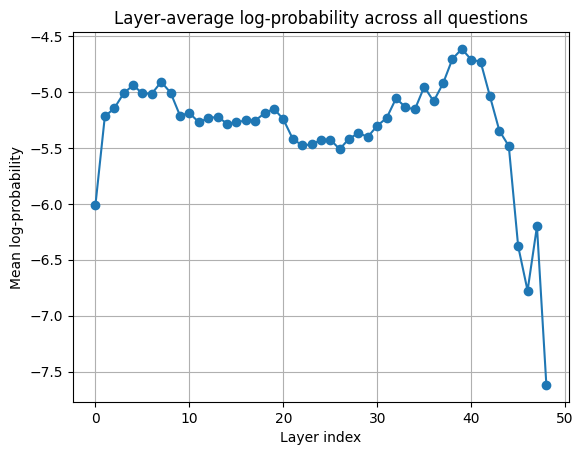

In [10]:
import matplotlib.pyplot as plt
import numpy as np

correct_rows = [r for r in rows if r.get("correct")]

# ─── gather every layer‑average vector ───────────────────────────────
layer_rows = []
for row in correct_rows:
    fname_key = "layer_avg_logp_file"
    if fname_key in row:                      # skip rows without the blob
        vec = torch.load(RUN_DIR / row[fname_key], map_location="cpu")
        # vec is either a 1‑D tensor or NumPy array
        layer_rows.append(np.asarray(vec))

if not layer_rows:
    raise ValueError("No layer_avg_logp_file entries found. Check your RUN_DIR.")

layer_matrix = np.stack(layer_rows)           # shape = (n_questions , n_layers)
mean_logp    = layer_matrix.mean(axis=0)      # (n_layers,)

# ─── plot ────────────────────────────────────────────────────────────
plt.figure()
plt.plot(range(len(mean_logp)), mean_logp, marker="o")  # default colours
plt.xlabel("Layer index")
plt.ylabel("Mean log‑probability")
plt.title("Layer‑average log‑probability across all questions")
plt.grid(True)
plt.show()

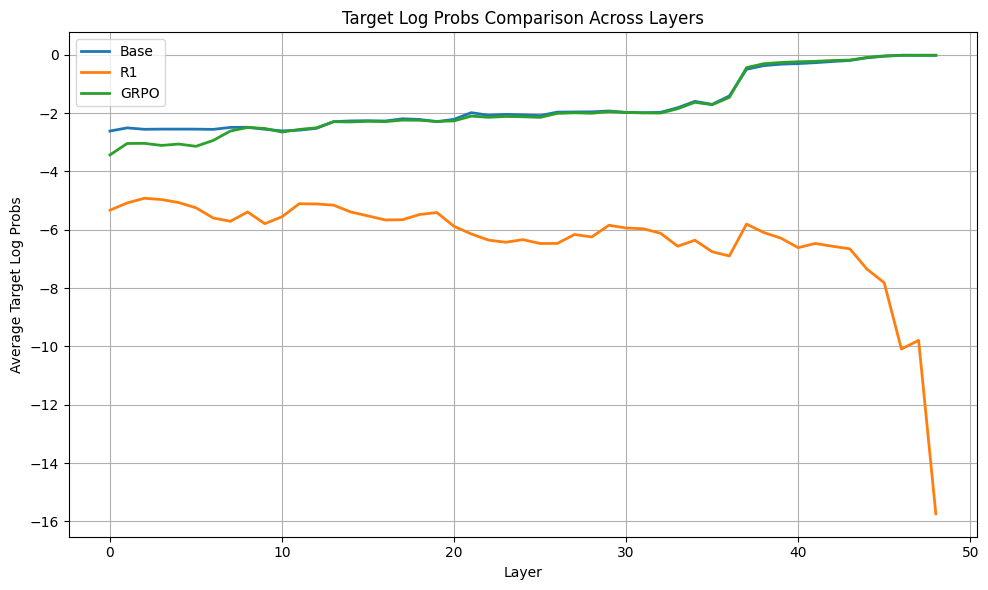

In [3]:
# Compute means
base_mean = base_lp_df.mean()
R1_mean = R1_lp_df.mean()
GRPO_mean = GRPO_lp_df.mean()

# Plot
plt.figure(figsize=(10, 6))
plt.plot(base_mean, label="Base", linewidth=2)
plt.plot(R1_mean, label="R1", linewidth=2)
plt.plot(GRPO_mean, label="GRPO", linewidth=2)

# Labels and legend
plt.xlabel("Layer")
plt.ylabel("Average Target Log Probs")
plt.title("Target Log Probs Comparison Across Layers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
